# Modelo final

In [1]:
import ast
import csv

import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

from utilidades import (ejecutar_configuracion, crear_dataloaders, evaluar, guardar_acc_test, dibujar_matriz_confusion,
                        desnormalizar, device)

print(f'Usando dispositivo: {device}')

Usando dispositivo: cpu


## Selección de la mejor configuración de la búsqueda manual

In [2]:
configuraciones_manuales = [f'C{numero}' for numero in range(1, 9)]

with open('resultados.csv', encoding='utf-8') as fichero:
    filas = [fila for fila in csv.DictReader(fichero) if fila['configuracion'] in configuraciones_manuales]

for fila in sorted(filas, key=lambda fila: float(fila['perdida_val'])):
    print(f'{fila["configuracion"]:3s} | loss val: {fila["perdida_val"]:6s} | acc val: {fila["acc_val"]:6s}')

mejor_fila = min(filas, key=lambda fila: float(fila['perdida_val']))
print(f'\nMejor configuración: {mejor_fila["configuracion"]}')
print(mejor_fila['hiperparametros'])

C8  | loss val: 0.0067 | acc val: 0.9983
C6  | loss val: 0.0085 | acc val: 0.9983
C5  | loss val: 0.0089 | acc val: 0.9978
C7  | loss val: 0.0089 | acc val: 0.9983
C3  | loss val: 0.009  | acc val: 0.9975
C2  | loss val: 0.0091 | acc val: 0.998 
C4  | loss val: 0.0103 | acc val: 0.998 
C1  | loss val: 0.0132 | acc val: 0.9955

Mejor configuración: C8
tam_imagen=128; tam_lote=64; lr=0.001; filtros=(16, 32, 64); neuronas_fc=(256, 128); activacion=LeakyReLU; p_dropout=0.5; aumentado=False; pesos_clase=False


In [3]:
valores = dict(par.split('=') for par in mejor_fila['hiperparametros'].split('; '))

mejor_configuracion = {
    'tam_imagen': int(valores['tam_imagen']),
    'tam_lote': int(valores['tam_lote']),
    'lr': float(valores['lr']),
    'filtros': ast.literal_eval(valores['filtros']),
    'neuronas_fc': ast.literal_eval(valores['neuronas_fc']),
    'activacion': getattr(nn, valores['activacion']),
    'p_dropout': float(valores['p_dropout']),
}
print(mejor_configuracion)

{'tam_imagen': 128, 'tam_lote': 64, 'lr': 0.001, 'filtros': (16, 32, 64), 'neuronas_fc': (256, 128), 'activacion': <class 'torch.nn.modules.activation.LeakyReLU'>, 'p_dropout': 0.5}


## Entrenamiento de la configuración elegida

Época [ 1/40] | Train Loss: 0.2326 | Train Acc: 0.9279 | Val Loss: 0.0318 | Val Acc: 0.9918 *
Época [ 2/40] | Train Loss: 0.0503 | Train Acc: 0.9881 | Val Loss: 0.0158 | Val Acc: 0.9955 *
Época [ 3/40] | Train Loss: 0.0462 | Train Acc: 0.9892 | Val Loss: 0.0128 | Val Acc: 0.9966 *
Época [ 4/40] | Train Loss: 0.0338 | Train Acc: 0.9916 | Val Loss: 0.0098 | Val Acc: 0.9963 *
Época [ 5/40] | Train Loss: 0.0444 | Train Acc: 0.9892 | Val Loss: 0.0118 | Val Acc: 0.9969 
Época [ 6/40] | Train Loss: 0.0381 | Train Acc: 0.9921 | Val Loss: 0.0091 | Val Acc: 0.9972 *
Época [ 7/40] | Train Loss: 0.0256 | Train Acc: 0.9948 | Val Loss: 0.0087 | Val Acc: 0.9983 *
Época [ 8/40] | Train Loss: 0.0225 | Train Acc: 0.9952 | Val Loss: 0.0115 | Val Acc: 0.9975 
Época [ 9/40] | Train Loss: 0.0206 | Train Acc: 0.9951 | Val Loss: 0.0139 | Val Acc: 0.9972 
Época [10/40] | Train Loss: 0.0224 | Train Acc: 0.9952 | Val Loss: 0.0142 | Val Acc: 0.9978 
Época [11/40] | Train Loss: 0.0220 | Train Acc: 0.9964 | Val Los

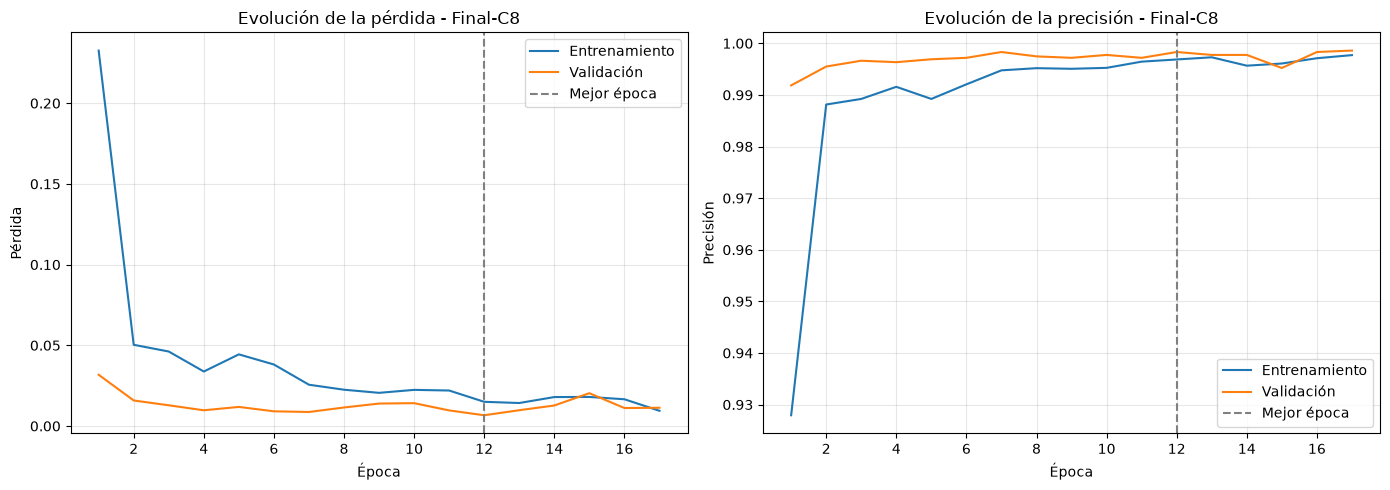

In [4]:
nombre_final = f'Final-{mejor_fila["configuracion"]}'

modelo_final, historial_final = ejecutar_configuracion(nombre_final, **mejor_configuracion)

## Evaluación en test

In [5]:
_, _, dataloader_test, clases = crear_dataloaders('datos', mejor_configuracion['tam_imagen'],
                                                  mejor_configuracion['tam_lote'])

y_real, y_pred, perdida_test, acc_test = evaluar(modelo_final, dataloader_test)
guardar_acc_test(nombre_final, acc_test)

print(f'Test Loss: {perdida_test:.4f} | Test Acc: {acc_test:.4f}')
print(classification_report(y_real, y_pred, target_names=clases, digits=4))

Test Loss: 0.0155 | Test Acc: 0.9969
              precision    recall  f1-score   support

     cushion     0.9922    1.0000    0.9961       510
     emerald     0.9980    0.9961    0.9971       510
       heart     1.0000    0.9980    0.9990       510
        oval     1.0000    1.0000    1.0000       510
        pear     0.9980    0.9941    0.9961       510
    princess     1.0000    0.9902    0.9951       510
       round     0.9903    1.0000    0.9951       510

    accuracy                         0.9969      3570
   macro avg     0.9969    0.9969    0.9969      3570
weighted avg     0.9969    0.9969    0.9969      3570



## Matriz de confusión

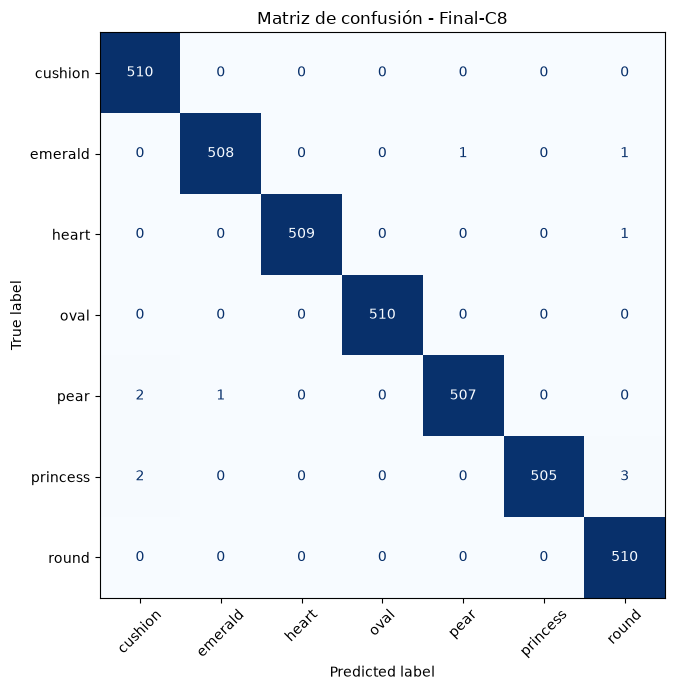

In [6]:
dibujar_matriz_confusion(y_real, y_pred, clases, nombre_final, f'graficas/matriz_{nombre_final}.png')

## Ejemplos mal clasificados

Imágenes mal clasificadas: 11 de 3570


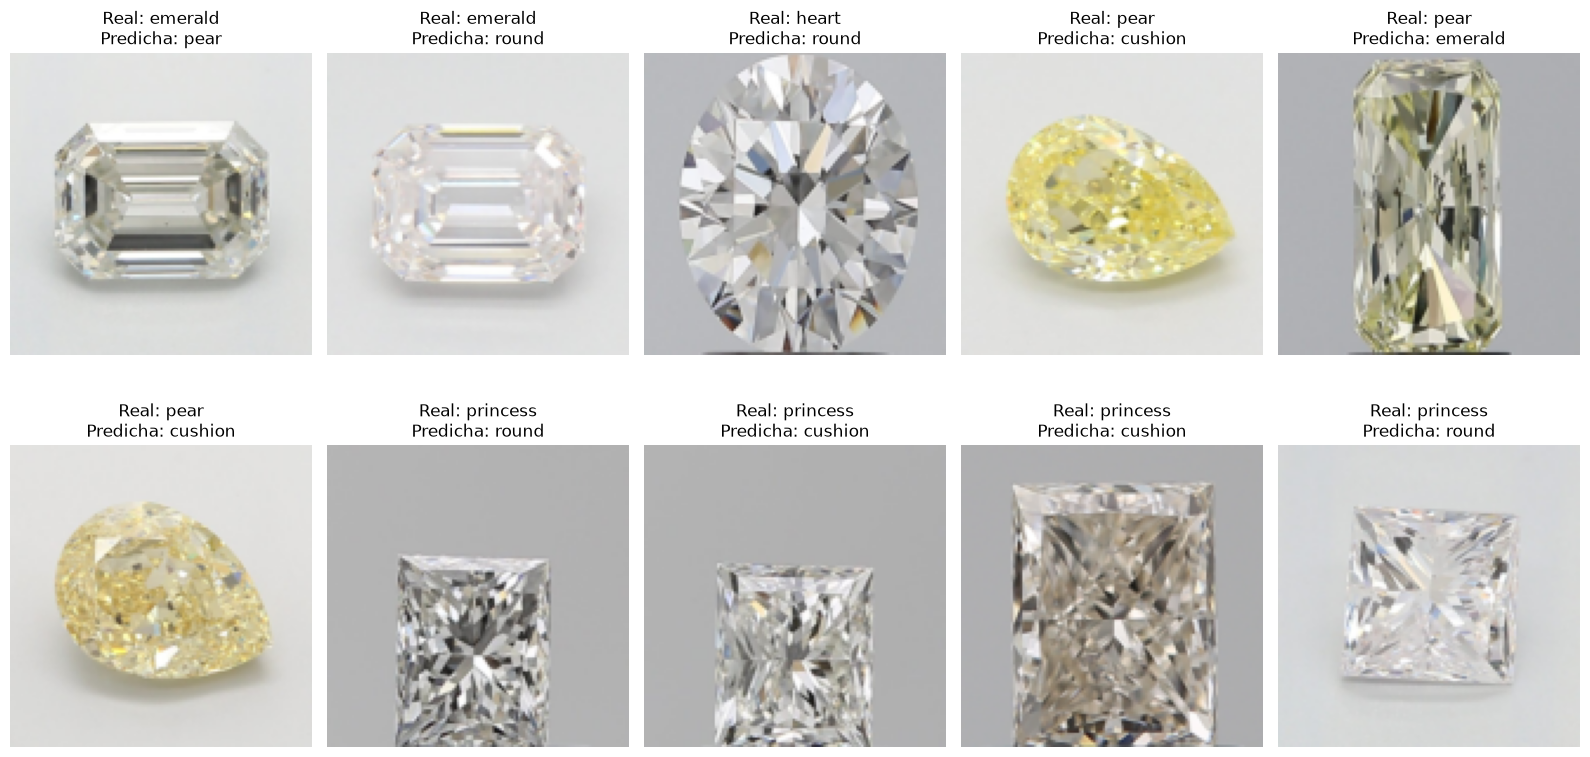

In [7]:
dataset_test = dataloader_test.dataset
indices_fallos = [indice for indice in range(len(y_real)) if y_real[indice] != y_pred[indice]]
print(f'Imágenes mal clasificadas: {len(indices_fallos)} de {len(y_real)}')

num_mostrar = min(len(indices_fallos), 10)
filas_figura = max((num_mostrar + 4) // 5, 1)

plt.figure(figsize=(16, 4.2 * filas_figura))
for posicion, indice in enumerate(indices_fallos[:num_mostrar]):
    imagen, _ = dataset_test[indice]
    plt.subplot(filas_figura, 5, posicion + 1)
    plt.imshow(desnormalizar(imagen))
    plt.title(f'Real: {clases[y_real[indice]]}\nPredicha: {clases[y_pred[indice]]}')
    plt.axis('off')
plt.tight_layout()
plt.savefig(f'graficas/fallos_{nombre_final}.png', dpi=120)
plt.show()